Simulation of the cell cycle and apoptosis model biochemically and in a cell population
=========

## 1 Simulation with the original parameters

The parameters refer to the biochemical constants. The first step is importing the model and dependencies. The model and the simulations are done within the package PySB [1].



In [1]:
import os
import sys
sys.path.insert(0, os.getcwd() + "/cellular_cycle") #add a pathway to the model #not sure about how to use folder dependency, to change
sys.path.insert(0, os.getcwd() + "/fit") #add a pathway to the fit functions #not sure about how to use folder dependency, to change

import numpy as np
import pandas as pd
import pylab as pl
import seaborn as sns

##Importing the model, models differ on their initial conditions, one being a concentration and the other a protein count
from Austin_proliferation_model_concentration_5 import model
model_concentration=model
from Austin_proliferation_model_population_5 import model
model_population=model

##Import the simulator: for ODE and stochastic simulation :
from pysb.simulator import BngSimulator
from pysb.simulator import ScipyOdeSimulator


#change the model parameters of the model if needed
omega = 200
new_param = pd.read_csv(os.getcwd() + "/../umap_window/parameters.csv") 
del new_param['Stress']
#for key in new_param.keys():
#    if model_population.parameters[key].value != new_param[key][0]:
#        model_population.parameters[key].value = new_param[key]
#    if model_concentration.parameters[key].value != new_param[key][0]:
#        model_concentration.parameters[key].value = new_param[key]

WARNING (theano.configdefaults): g++ not available, if using conda: `conda install m2w64-toolchain`
WARNING (theano.configdefaults): g++ not detected ! Theano will be unable to execute optimized C-implementations (for both CPU and GPU) and will default to Python implementations. Performance will be severely degraded. To remove this warning, set Theano flags cxx to an empty string.
WARNING (theano.tensor.blas): Using NumPy C-API based implementation for BLAS functions.


## 2 Simulation of biochemical modem

Now we execute the model with the original parameters and the initial conditions. Let's start with simulating the biochemical model with a set of ordinary differential equations and then with the Gillespie's Stochastic Simulation Algorithm both available in the PySB package.

### Deteriministic simulation


2022-08-15 21:59:40.810 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing a package for compiling the ODEs to C code: 'weave' (recommended for Python 2) or 'cython' (recommended for Python 3). This warning can be suppressed by specifying compiler='python'.


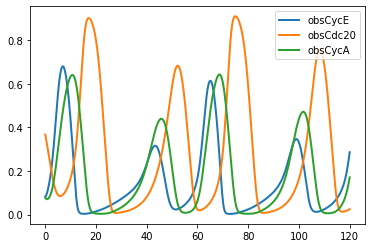

In [3]:
#ODE simulation

t = pl.linspace(0, 120, 120000)
simres = ScipyOdeSimulator(model_concentration, t, verbose=False).run(); #deterministic simulation
yout = simres.all;
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A

for obs in range(3) :
    pl.plot(t,yout[observables[obs]], label=observables[obs], lw=2)
pl.legend(loc=0)
pl.show()


### Stochastic simulation


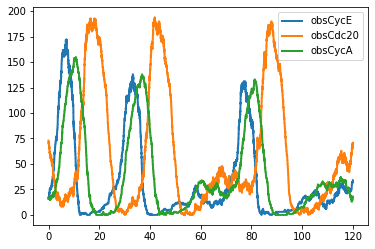

In [4]:
#Stochastic simulation
t = pl.linspace(0, 120, 170000);
sim = BngSimulator(model_population, tspan=t, verbose=False); #stochastic simulator
simres = sim.run(method='ssa', verbose=False); #running the simulation
yout = simres.observables;
observables=['obsCycE','obsCdc20', 'obsCycA']; #plot Cyclin E, Cdc20 and Cyclin A


for obs in range(3) :    
    pl.plot(t,yout[observables[obs]], label=observables[obs], lw=2)
pl.legend(loc=0)
pl.show()


## 3 Simulation of a population of cells

In order to reproduce faithfully the experiments we run a population of cells. Each events is registered, if death occurs the simulation stops, if a mitosis occurs, a new simulation occurs from the division time.

### Simulating the population


In [ ]:
#from runAKTERK_2_starting_at_mitosis import runAKTERK #Cell population simulation
#from runStochCell import runStochcell #Simulate the biochemical model with ODEs
from runAKTERK_2 import runAKTERK #Simulate a population of cells from independants biochemical models
from runStochCell import runStochcell

from retrieve_cellState_dw import retrieve_cellState #
from call_cell_events import call_events #

import fracprolif as fp
import random
from rbf_mmd import nmmd2_rbf

run_time=120 #how long is the experiment
observed_cells_time=120 #how long are we looking at new cells
nber_of_starting_cells=6 #size of initial population
index="_" #to be removed...
condition="_" #to be removed...


#(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);
(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);
#index and conditions to save the identity of the simulation (to remove?)


(0.0, 110.0)

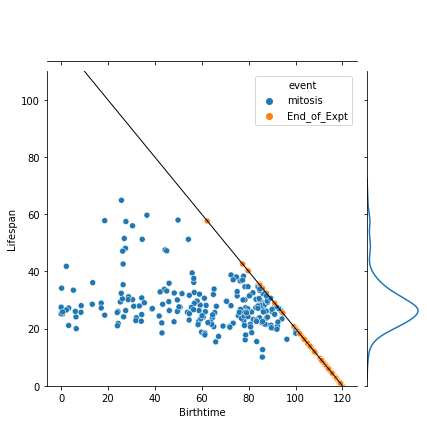

In [19]:
from plot_frac_div_q_ap1 import all_events #

IMT_eoe_counts = retrieve_cellState(run_time, nber_of_starting_cells, cells); #Gives the cells life per cycle
all_events_simulated = all_events(run_time, IMT_eoe_counts); #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'], ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
pl.ylim(0, 110)

(0.0, 110.0)

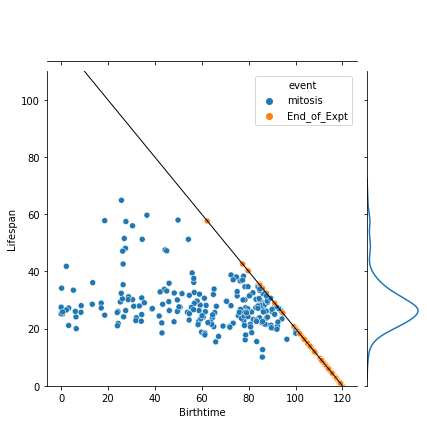

In [18]:
from call_cell_events import call_events #

IMT_eoe_counts = retrieve_cellState(run_time, nber_of_starting_cells, cells); #Gives the cells life per cycle
all_events_simulated = all_events(run_time, IMT_eoe_counts); #Gives all events (apoptosis, mitosis, quiescence) and when they happen

#plot the results
grid = sns.JointGrid(x='Birthtime', y='Lifespan', data=all_events_simulated) #x axis = birthtime of a cell, y = endtime of this cell
g = grid.plot_joint(sns.scatterplot, hue='event', data=all_events_simulated) 
g.ax_joint.plot([run_time, 0], [0, run_time], 'b-', linewidth = 1, color='black') #Recorded events behind this line
sns.kdeplot(all_events_simulated.loc[all_events_simulated['event']=='mitosis', 'Lifespan'], ax=g.ax_marg_y, vertical=True, legend=False, bw=0.3) #output distribution of intermitotic times
pl.ylim(0, 110)

In [15]:
print(cells.keys()) #different components of 'cells', molecules are all the time courses
len(cells['molecules']) #number of cells life (starts at a mitosis event or time 0 of the experiment and ends at a mitosis, cell death or end of the experiment)

#example
#[cells['molecules'][i]['obsSkp2'] for i in range(len(cells['molecules']))] #all time courses of  Skp2 concatenated

#we iterates over all the cells for all the observable proteins and make it a Dataframe with column=proteins
prot_all = pd.DataFrame(np.array([np.concatenate([cells['molecules'][i][obs.name] for i in range(len(cells['molecules']))]) for obs in model_concentration.observables]).T, columns = [obs.name.replace('obs','') for obs in model_concentration.observables])

#total observed time
print(str(len(prot_all) * (cells['time'][0][1] - cells['time'][0][0])) + ' hours')

#np.array([np.concatenate([cells['molecules'][i][obs.name] for i in range(len(cells['molecules']))]) for obs in model_concentration.observables]).shape
prot_all.head()



dict_keys(['molecules', 'time', 'division', 'living_cell', 'recording'])
12803.819095475596 hours


,Skp2,p21,p21p,cdh1act,cdh1inact,Myc,CycD,CycDp21,pRb,pRbp,...,CycAp21,CycB,CycBp21,Cdc20,BAX,BAXmBCL2,BH3,BH3BCL2,BAXm,BCL2
0,14.0,8.0,5.0,3.0,197.0,64.0,34.0,2.0,112.0,63.0,...,10.0,135.0,1.0,122.0,186.0,13.0,0.0,7.0,0.0,170.0
1,14.0,8.0,6.0,3.0,197.0,61.0,35.0,2.0,114.0,60.0,...,9.0,137.0,1.0,127.0,186.0,13.0,0.0,7.0,0.0,170.0
2,14.0,5.0,3.0,7.0,193.0,63.0,35.0,2.0,113.0,61.0,...,10.0,135.0,1.0,130.0,186.0,13.0,0.0,7.0,0.0,170.0
3,15.0,7.0,3.0,4.0,196.0,64.0,34.0,2.0,129.0,47.0,...,10.0,136.0,1.0,130.0,183.0,16.0,0.0,7.0,0.0,167.0
4,15.0,5.0,2.0,1.0,199.0,63.0,34.0,2.0,122.0,55.0,...,10.0,139.0,1.0,132.0,183.0,16.0,0.0,7.0,0.0,167.0


### Calculating the parameters assuming the fractional proliferation model
We can calculated the parameters associated with the fractional proliferation model

*Recall the formula for fractional proliferation model + ref


In [7]:

mitotic_lifespans = all_events_simulated['Lifespan'][all_events_simulated['event']=='mitosis']
censored_lifespans = all_events_simulated['Lifespan'][all_events_simulated['event']=='End_of_Expt']

number_of_deaths = len(all_events_simulated) - (all_events_simulated['event']=='apoptosis').value_counts()[0]
cell_time_total = sum(all_events_simulated['Lifespan'])
print("death rate = " + str(number_of_deaths/cell_time_total)) #death rate (death event/time)


m = fp.mle(mitotic_lifespans, censored_lifespans);
print("μ = " + str(m['x'][0])) #mu
print("σ = " + str(m['x'][1])) #sigma
print("λ = " + str(m['x'][2])) #lambda


death rate = 0.0
μ = 20.428742080641634
σ = 4.477615517035742
λ = 0.1259820598066768


### Calculating a cost for this set of parameters

Once the simulation is done we can calculate a cost associated with the parameters. Let's try with our initial parameters.
We have two conditions: high and low stiffness (55 and 0.6 kPa). We change the signaling input FAK, ERK and AKT as entries in the model to simulate these different conditions. Then the parameters of the fractional proliferation model are calculated and the difference between the intermitotic distribution for the low stiffness and the difference between the G1 and S to M time distribution for the high stiffness.

##### Importing experimental data

In [31]:
#0.6 kPa low stiffness

all_events_exp = {}
IMT_eoe_counts = pd.DataFrame(columns=['End_of_Expt', 'Death' ,'Birthtime','Lifespan'])
dataframe = pd.read_csv(os.getcwd() + r'/cell_fates/ds8_06_DMSO_fates.csv')
lines = {}
for col in dataframe :
    lines[col]=dataframe[col].dropna().tolist()

for (death, mitotic_time, end_time, lifetime) in zip(lines['Death'], lines['Mitotic Time'], lines['End Time'], lines['Lifetime']):
    tmp_counts = {'End_of_Expt' : end_time==102.3, 'Death' : death==1, 'Birthtime' : mitotic_time, 'Lifespan' : lifetime}
    IMT_eoe_counts = IMT_eoe_counts.append(tmp_counts, ignore_index=True)

all_events_exp['0.6 kPa DMSO'] = call_events(run_time, IMT_eoe_counts)
mitotic_lifespans_exp = all_events_exp['0.6 kPa DMSO']['Lifespan'][all_events_exp['0.6 kPa DMSO']['event']=='mitosis']
censored_lifespans_exp = all_events_exp['0.6 kPa DMSO']['Lifespan'][all_events_exp['0.6 kPa DMSO']['event']=='End_of_Expt']
number_of_deaths = len(all_events_exp['0.6 kPa DMSO']) - (all_events_exp['0.6 kPa DMSO']['event']=='apoptosis').value_counts()[0]
cell_time_total = sum(all_events_exp['0.6 kPa DMSO']['Lifespan'])
m = fp.mle(mitotic_lifespans_exp, censored_lifespans_exp)
parameters_exp={}
parameters_exp['0.6 kPa DMSO'] ={}
parameters_exp['0.6 kPa DMSO']['a'] = number_of_deaths/cell_time_total
parameters_exp['0.6 kPa DMSO']['mu'] = m['x'][0]
parameters_exp['0.6 kPa DMSO']['sigma'] = m['x'][1]
parameters_exp['0.6 kPa DMSO']['lambda'] = m['x'][2]
parameters_exp['0.6 kPa DMSO'].update(fp.q_rates(m))


#55 kPa high stiffness #importing G1 and S to M time (0.2 kPa to be removed)
experimental_SMs={}
experimental_G1s={}

dataframe = pd.read_csv(os.getcwd() + r'/IMT_times/DS8_SM_0_2_55.csv') 
for col in dataframe.columns :
    experimental_SMs[col]=dataframe[col].dropna().tolist()
dataframe = pd.read_csv(os.getcwd() + r'/IMT_times/DS8_G1_0_2_55.csv')
for col in dataframe.columns :
    experimental_G1s[col]=dataframe[col].dropna().tolist()


##### Low stiffness

In [35]:
from runAKTERK_2_starting_at_mitosis import runAKTERK #Cell population simulation
import random

run_time=102.3 #how long is the experiment
observed_cells_time=30 #how long are we looking at new cells
nber_of_starting_cells=50 #size of initial population
index="_" #to be removed...

#Input of the model: Activation of different signalling pathway measured with Western blot
condition = '0.6 kPa DMSO'
model_concentration.parameters['ERK'].value = 1.06970165050038 
model_concentration.parameters['FAK'].value = 0.337143388171177
model_concentration.parameters['AKT'].value = 0.616658111482869
model_population.parameters['ERK'].value = 1.06970165050038 * 200
model_population.parameters['FAK'].value = 0.337143388171177 * 200
model_population.parameters['AKT'].value = 0.616658111482869 * 200

#Setting the cost to zero
parameters_sim={}
cost_frac_prolif_model_006=0
cost_mmd_006=0
cost_006=0

#Simulation of the cell population
(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);
IMT_eoe_counts = retrieve_cellState(run_time, nber_of_starting_cells, cells)
all_events_simulated = call_events(run_time, IMT_eoe_counts)
all_events_simulated = all_events_simulated[np.array(all_events_simulated['Birthtime']<30)] #We kept the events whose birthtime is inferior to 30 hours to compare to the experiments.
mitotic_lifespans = all_events_simulated['Lifespan'][all_events_simulated['event']=='mitosis']
censored_lifespans = all_events_simulated['Lifespan'][all_events_simulated['event']=='End_of_Expt']

#calculating fractional proliferation model parameters
number_of_deaths = len(all_events_simulated) - (all_events_simulated['event']=='apoptosis').value_counts()[0]
cell_time_total = sum(all_events_simulated['Lifespan'])
m = fp.mle(mitotic_lifespans, censored_lifespans)
parameters_sim[condition] = {}
parameters_sim[condition]['a'] = number_of_deaths/cell_time_total
parameters_sim[condition]['mu'] = m['x'][0]
parameters_sim[condition]['sigma'] = m['x'][1]
parameters_sim[condition]['lambda'] = m['x'][2]
parameters_sim[condition].update(fp.q_rates(m))
for name in ['a','d','q']: #apoptosis, division and quiescence rates
    if parameters_exp[condition][name]<10**-5:
        parameters_exp[condition][name] = 1e-5
    if parameters_sim[condition][name]<10**-5:
        parameters_sim[condition][name] = 1e-5
    cost_frac_prolif_model_006 += abs(np.log(parameters_sim[condition][name]) - np.log(parameters_exp[condition][name]))
            

#comparing distributions
number_of_IMT_to_sample=72
simulated_IMT = random.sample(mitotic_lifespans.to_list(), number_of_IMT_to_sample)
experimental_IMT = random.sample(mitotic_lifespans_exp.to_list(), number_of_IMT_to_sample)
cost_mmd_006 += nmmd2_rbf(np.array([simulated_IMT]).transpose(), np.array([experimental_IMT]).transpose(), 1) #difference between IMT distribution


#Adding the two costs
cost_006 += cost_frac_prolif_model_006 + cost_mmd_006

print(cost_006) 

14.628301087374016


##### High stiffness
In this case we compare the distribution of G1 and S to M time to the experimental data.

In [36]:
init = 30
run_time = 102.3 #how long is the experiment
observed_cells_time = 30 #how long are we looking at new cells
nber_of_starting_cells = 50 #size of initial population
index = "_" #to be removed...
cost_mmd_55 = 0 #set the cost to zero

#Input of the model: Activation of different signalling pathway measured with Western blot
condition = '55 kPa DMSO'
model_concentration.parameters['ERK'].value = 1
model_concentration.parameters['FAK'].value = 1
model_concentration.parameters['AKT'].value = 1
model_population.parameters['ERK'].value = 1 * 200
model_population.parameters['FAK'].value = 1 * 200
model_population.parameters['AKT'].value = 1 * 200

#Simulation of the cell population
(cells, cell_count) = runAKTERK(nber_of_starting_cells, run_time, observed_cells_time, model_concentration, model_population, index, condition);
IMT_eoe_counts = retrieve_cellState(run_time, nber_of_starting_cells, cells)
all_events_simulated = call_events(run_time, IMT_eoe_counts)
all_events_simulated = all_events_simulated[np.array(all_events_simulated['Birthtime']<30)] #We kept the events whose birthtime is inferior to 30 hours to compare to the experiments.
mitotic_lifespans = all_events_simulated['Lifespan'][all_events_simulated['event']=='mitosis']
censored_lifespans = all_events_simulated['Lifespan'][all_events_simulated['event']=='End_of_Expt']

#Comparing G1 and S to M distribution
number_of_SM_to_sample=160
number_of_G1_to_sample=160
simulated_G1s = random.sample(simulated_g1, number_of_G1_to_sample)
experimental_G1s_picked = random.sample(experimental_G1s['55 kPa DMSO'], number_of_G1_to_sample)
simulated_SMs = random.sample(simulated_sm, number_of_SM_to_sample)
experimental_SMs_picked = random.sample(experimental_SMs['55 kPa DMSO'], number_of_SM_to_sample)
cost_mmd_55 += nmmd2_rbf(np.array([simulated_G1s]).transpose(), np.array([experimental_G1s_picked]).transpose(), 1) #difference between IMT distribution
cost_mmd_55 += nmmd2_rbf(np.array([simulated_SMs]).transpose(), np.array([experimental_SMs_picked]).transpose(), 1) #difference between IMT distribution

print(cost_mmd_55)

2021-08-09 22:47:58.890 - pysb.simulator.scipyode - WARNING - [Austin_proliferation_ODE_model_5] This system of ODEs will be evaluated in pure Python. This may be slow for large models. We recommend installing a package for compiling the ODEs to C code: 'weave' (recommended for Python 2) or 'cython' (recommended for Python 3). This warning can be suppressed by specifying compiler='python'.


## 4 Simulation with the fitted parameters

#### Sobol sequence
From the Sobol sequence

In [8]:
frac_prolif_parameters = pd.read_pickle(os.getcwd() + "/fit_data/sobol_seq/frac_prolif_parameters_all_parameters_006_55_kPa.pkl")

#Original parameters
pysb_sampled_parameter_names = ["V_s2skp","V_Fp","k_M","k_EMY","k_CDF","k_CDS","k_ED","K_S","K_MY","K_DF","d_CD","k_P1", "k_P2", "K_CD", "k_E", "K_M", "K_CE", "V_2E2F", "K_2E2F", "k_RE", "kf1", "kf2", "kb", "kasbaxmbcl2", "kdsbaxmbcl2", "k1sbh3", "k2sbh3", "kdbh3", "kasbh3bcl2", "kdsbh3bcl2"]
loc=[]
for parameter in pysb_sampled_parameter_names:
    loc+=[np.log10(model.parameters[parameter].value)] 


#Generating the sobol sequence
import sobol_seq
l = sobol_seq.i4_sobol_generate(30, 140000, skip = 0)
l2 = 4*l + (np.array(loc)-2)

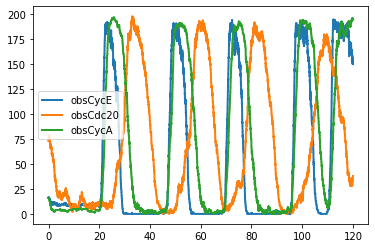

In [9]:
#indices in the sobol sequence for the 100 best parameters
indices = [int(i)-1 for i in frac_prolif_parameters.sort_values(by=['cost_total'])["index"].tolist()[0:100]] 
parameters = [l2[i] for i in indices]

#Change model parameter values to current location in parameter space
parameter_vector = 10**parameters[0] #original parameters
param_dict = {pname: pvalue for pname, pvalue in zip(pysb_sampled_parameter_names, parameter_vector)}   
for pname, pvalue in param_dict.items():
    model_population.parameters[pname].value = (pvalue)
    model_concentration.parameters[pname].value = (pvalue)

sim = BngSimulator(model_population, tspan=t, verbose=False);
simres2 = sim.run(method='ssa', verbose=False);
yout = simres2.observables;
observables=['obsCycE','obsCdc20', 'obsCycA'];


for obs in range(3) :    
    pl.plot(t,yout[observables[obs]], label=observables[obs], lw=2)
pl.legend(loc=0)
pl.show()

#### Particle Swarm Optimization


In [6]:
frac_prolif_parameters = pd.read_pickle(os.getcwd() + "/fit_data/sobol_seq/frac_prolif_parameters_all_parameters_006_55_kPa.pkl")


In [7]:
#importing parameters from the pso space exploration

frac_prolif_parameters = pd.read_pickle(os.getcwd() + "/fit_data/sobol_seq/frac_prolif_parameters_all_parameters_006_55_kPa.pkl")
position_history = np.load(os.getcwd() + "/fit_data/pso/position_history.npy", allow_pickle=True)
particle_positions_pso = pd.read_pickle(os.getcwd() + "/fit_data/pso/particle_position_all_parameters_pso.pkl")
frac_prolif_parameters_pso = pd.read_pickle(os.getcwd() + "/fit_data/pso/frac_prolif_parameters_pso.pkl")

#Parameters sampled from the simulation

parameters_log_best=[]
cost_limit = frac_prolif_parameters.sort_values(by=['cost_total'])[0:1]['cost_total'].tolist()[-1] #set the cost limit to the best found in sobol sequence, can be changed
frac_prolif_parameters_pso['cost_total'].tolist()
for idx in frac_prolif_parameters_pso['index']:
    if frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['index']==idx].iloc[0]['cost_total']<cost_limit: #select the cost  lower than cost limit
        #print(idx)
        frac_prolif_parameters_pso_temp = frac_prolif_parameters_pso.loc[frac_prolif_parameters_pso['index']==idx]
        parameter = particle_positions_pso[particle_positions_pso['identification']==idx]['parameter_vector'].iloc[0]
        pos = np.where(position_history[:,:,:] == parameter)
        position_history[pos[0][0],pos[1][0],:]
        parameters_log_best += [position_history[pos[0][0],pos[1][0],:].tolist()]


parameters_log_best = np.array(parameters_log_best) #here is the set of parameters, note it's a log scale
len(parameters_log_best)



023220664558835757
0293019570479498
041141902146878184
05112194312019136
08340282694177947
08986242226604702
18698745662842597
22140641640866032
22425787817149145
28397742853454855
2916722843821321
33397850315113375
40282144079727955
44303351623592657
45606113197181997
4617528175345129
46213491973507403
49058803453988853
5302364584699781
539659678713794
5612515478469426
5615583558580135
5696587150187522
5842849676275806
6031435799647052
6430721240285013
6789925878049262
6839095067025954
7141836065969955
7160823302392836
764989573463899
7662561281661319
7699283696188989
8292062163488219
8339420378476092
8552679968736032
8577264532474786
9058614909214328
9092799669170852
9113307081796448
9381273257209515
9452080448585163
9577735187633011
9612156169152798
04058688609477057
048322208646213394
05495401710756431
05832427606945245
12070211228027616
13236981977440287
16829496896182483
19056642554376335
19328296816045554
22506682104514175
23225129580006343
2350219107411281
24642419025455997
251

266

2021-10-04 18:38:46.647 - pysb.simulator.bng - DEBUG - [Austin_proliferation_model_5] Simulator created
2021-10-04 18:38:46.652 - pysb.simulator.bng - INFO - [Austin_proliferation_model_5] Simulation(s) started
2021-10-04 18:38:47.373 - pysb.simulator.bng - INFO - [Austin_proliferation_model_5] Running 1 BNG ssa simulations
2021-10-04 18:38:47.377 - pysb.bng - DEBUG - [Austin_proliferation_model_5] <class 'pysb.bng.BngFileInterface'> instantiated in directory C:\Users\Grim.M\AppData\Local\Temp\tmpBNGqdjjmyor
2021-10-04 18:38:47.572 - pysb.bng - DEBUG - [Austin_proliferation_model_5] BNG command file contents:
L001  begin model
L002  begin parameters
L003    omega               2.000000e+02
L004    AKT                 2.000000e+02
L005    ERK                 2.000000e+02
L006    FAK                 2.000000e+02
L007    m                   3.000000e+00
L008    BCL2t               9.500000e-01
L009    BAXt                1.000000e+00
L010    kf1                 1.836570e-01
L011    kf2   

2021-10-04 18:38:48.443 - pysb.bng - DEBUG - [Austin_proliferation_model_5] BioNetGen version 2.5.0
2021-10-04 18:38:48.445 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Reading from file C:\Users\Grim.M\AppData\Local\Temp\tmpBNGqdjjmyor\pysb.bngl (level 0)
2021-10-04 18:38:48.504 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Read 202 parameters.
2021-10-04 18:38:48.505 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Read 14 molecule types.
2021-10-04 18:38:48.517 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Read 25 observable(s).
2021-10-04 18:38:48.539 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Read 26 functions.
2021-10-04 18:38:48.551 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Read 25 species.
2021-10-04 18:38:48.652 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Read 54 reaction rule(s).
2021-10-04 18:38:48.654 - pysb.bng - DEBUG - [Austin_proliferation_model_5] ACTION: generate_network( pysb )
2021-10-04 18:38:48.675 - pysb.bng - DEBU

2021-10-04 18:38:48.830 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Rule  51:     1 reactions 0.00e+000 CPU s 0.00e+000 CPU s/rxn
2021-10-04 18:38:48.831 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Rule  52:     1 reactions 0.00e+000 CPU s 0.00e+000 CPU s/rxn
2021-10-04 18:38:48.831 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Rule  53:     2 reactions 1.60e-002 CPU s 8.00e-003 CPU s/rxn
2021-10-04 18:38:48.832 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Rule  54:     1 reactions 0.00e+000 CPU s 0.00e+000 CPU s/rxn
2021-10-04 18:38:48.833 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Total   :    61 reactions 9.40e-002 CPU s 1.54e-003 CPU s/rxn
2021-10-04 18:38:48.834 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Wrote network in net format to pysb.net.
2021-10-04 18:38:48.835 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: generate_network 0.14 s.
2021-10-04 18:38:48.835 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNIN

2021-10-04 18:38:48.887 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:48.888 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'Yap_tot'
2021-10-04 18:38:48.889 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter Yap_tot to value 1
2021-10-04 18:38:48.890 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:48.891 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'AKT_tot'
2021-10-04 18:38:48.892 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter AKT_tot to value 1
2021-10-04 18:38:48.893 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:48.894 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'ERK_tot'
2021-10-04 18:38:48.895 - pysb.bng - D

2021-10-04 18:38:48.946 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:48.947 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_1cdc20'
2021-10-04 18:38:48.948 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter V_1cdc20 to value 1.8
2021-10-04 18:38:48.949 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:48.949 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_2cdc20'
2021-10-04 18:38:48.950 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter V_2cdc20 to value 0.6
2021-10-04 18:38:48.951 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:48.952 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_1E2F'
2021-10-04 18:38:48.953 - pysb.

...

2021-10-04 18:38:49.076 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_sec'
2021-10-04 18:38:49.077 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter V_sec to value 0.7
2021-10-04 18:38:49.077 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.078 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_de'
2021-10-04 18:38:49.079 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter V_de to value 0.75
2021-10-04 18:38:49.080 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.081 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_sf'
2021-10-04 18:38:49.082 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter V_sf to value 0.4
2021-10-04 18:38:49.083 - pysb.bng - DEBUG - 

2021-10-04 18:38:49.138 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'K_dp21p'
2021-10-04 18:38:49.139 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter K_dp21p to value 0.1
2021-10-04 18:38:49.140 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.141 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'K_dp21skp2'
2021-10-04 18:38:49.141 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter K_dp21skp2 to value 0.1
2021-10-04 18:38:49.142 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.143 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'K_cdh1'
2021-10-04 18:38:49.144 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter K_cdh1 to value 0.4
2021-10-04 18:38:49.145 - 

2021-10-04 18:38:49.223 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter k_c7 to value 0.12
2021-10-04 18:38:49.224 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.225 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'k_c8'
2021-10-04 18:38:49.226 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter k_c8 to value 0.2
2021-10-04 18:38:49.227 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.228 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'V_Fp'
2021-10-04 18:38:49.229 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter V_Fp to value 0.463762
2021-10-04 18:38:49.231 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.232 - pysb.bng - DEBUG - [Austin_proliferation_model_

2021-10-04 18:38:49.292 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.293 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'CycBp21_0'
2021-10-04 18:38:49.294 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter CycBp21_0 to value 0
2021-10-04 18:38:49.295 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.296 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'Cdc20_0'
2021-10-04 18:38:49.297 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set parameter Cdc20_0 to value 73
2021-10-04 18:38:49.298 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setParameter 0.00 s.
2021-10-04 18:38:49.299 - pysb.bng - DEBUG - [Austin_proliferation_model_5] WARNING: Changing value of previously defined variable 'BAX_0'
2021-10-04 18:38:49.300 - pysb.bng 

2021-10-04 18:38:49.359 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set concentration of species BCL2(b!1).BH3(b!1) to value 40
2021-10-04 18:38:49.360 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setConcentration 0.00 s.
2021-10-04 18:38:49.360 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set concentration of species BAX(b,m~yes) to value 0
2021-10-04 18:38:49.361 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setConcentration 0.00 s.
2021-10-04 18:38:49.362 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Set concentration of species BCL2(b) to value 149
2021-10-04 18:38:49.364 - pysb.bng - DEBUG - [Austin_proliferation_model_5] CPU TIME: setConcentration 0.00 s.
2021-10-04 18:38:49.364 - pysb.bng - DEBUG - [Austin_proliferation_model_5] ACTION: simulate( method=>"ssa" )
2021-10-04 18:38:49.365 - pysb.bng - DEBUG - [Austin_proliferation_model_5] Network simulation using ssa
2021-10-04 18:38:49.366 - pysb.bng - DEBUG - [Austin_prolifer

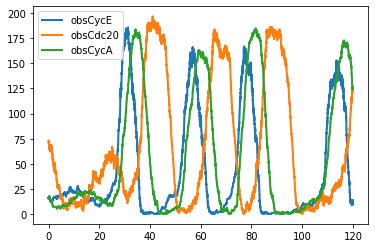

In [10]:
#parameters_log_best is the list of parameters

parameter_vector = 10**parameters_log_best[1]

param_dict = {pname: pvalue for pname, pvalue in zip(pysb_sampled_parameter_names, parameter_vector)}   
for pname, pvalue in param_dict.items():
    #Change model parameter values to current location in parameter space
    model_population.parameters[pname].value = (pvalue)
    model_concentration.parameters[pname].value = (pvalue)


sim = BngSimulator(model_population, tspan=t, verbose=False);
simres2 = sim.run(method='ssa', verbose=False);
yout = simres2.observables;
observables=['obsCycE','obsCdc20', 'obsCycA'];


for obs in range(3) :    
    pl.plot(t,yout[observables[obs]], label=observables[obs], lw=2)
pl.legend(loc=0)
pl.show()

### Bibliography 

[1]